In [1]:
%cd ..


/home/willraftery/PhD/projects/github/emg-stream


In [2]:
from pathlib import Path
import os
import h5py
import scipy.io


In [3]:


path = "data/ninapro_db5/S2_E2_A1.mat"

mat = scipy.io.loadmat(path)
print(mat.keys())

dict_keys(['__header__', '__version__', '__globals__', 'emg', 'acc', 'stimulus', 'glove', 'subject', 'exercise', 'repetition', 'restimulus', 'rerepetition', 'age', 'circumference', 'frequency', 'gender', 'height', 'weight', 'laterality', 'sensor'])


In [4]:
print(mat['emg'].shape)  # (number of samples, number of electrodes)
print(mat['acc'].shape)
print(mat['stimulus'].shape)  # (number of samples, 1)
print(mat['glove'].shape)
print(mat['subject'])
print(mat['exercise'])
print(mat['repetition'].shape)
print(mat['frequency'])
print(mat['sensor'])

(203945, 16)
(203945, 3)
(203945, 1)
(203945, 22)
[[11]]
[[1]]
(203945, 1)
[[200]]
['Double Myo']


In [5]:
import numpy as np
emg = mat['emg']  # (number of samples, number of electrodes)
emg = np.array(emg, dtype=np.float32)
print(np.max(np.abs(emg)))  # Check the max absolute value for normalization

128.0


In [6]:
stimulus = mat['stimulus']
repetition = mat['repetition']

print(np.unique(stimulus))  # Unique gesture labels
print(np.unique(repetition))  # Unique repetition numbers

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
[0 1 2 3 4 5 6]


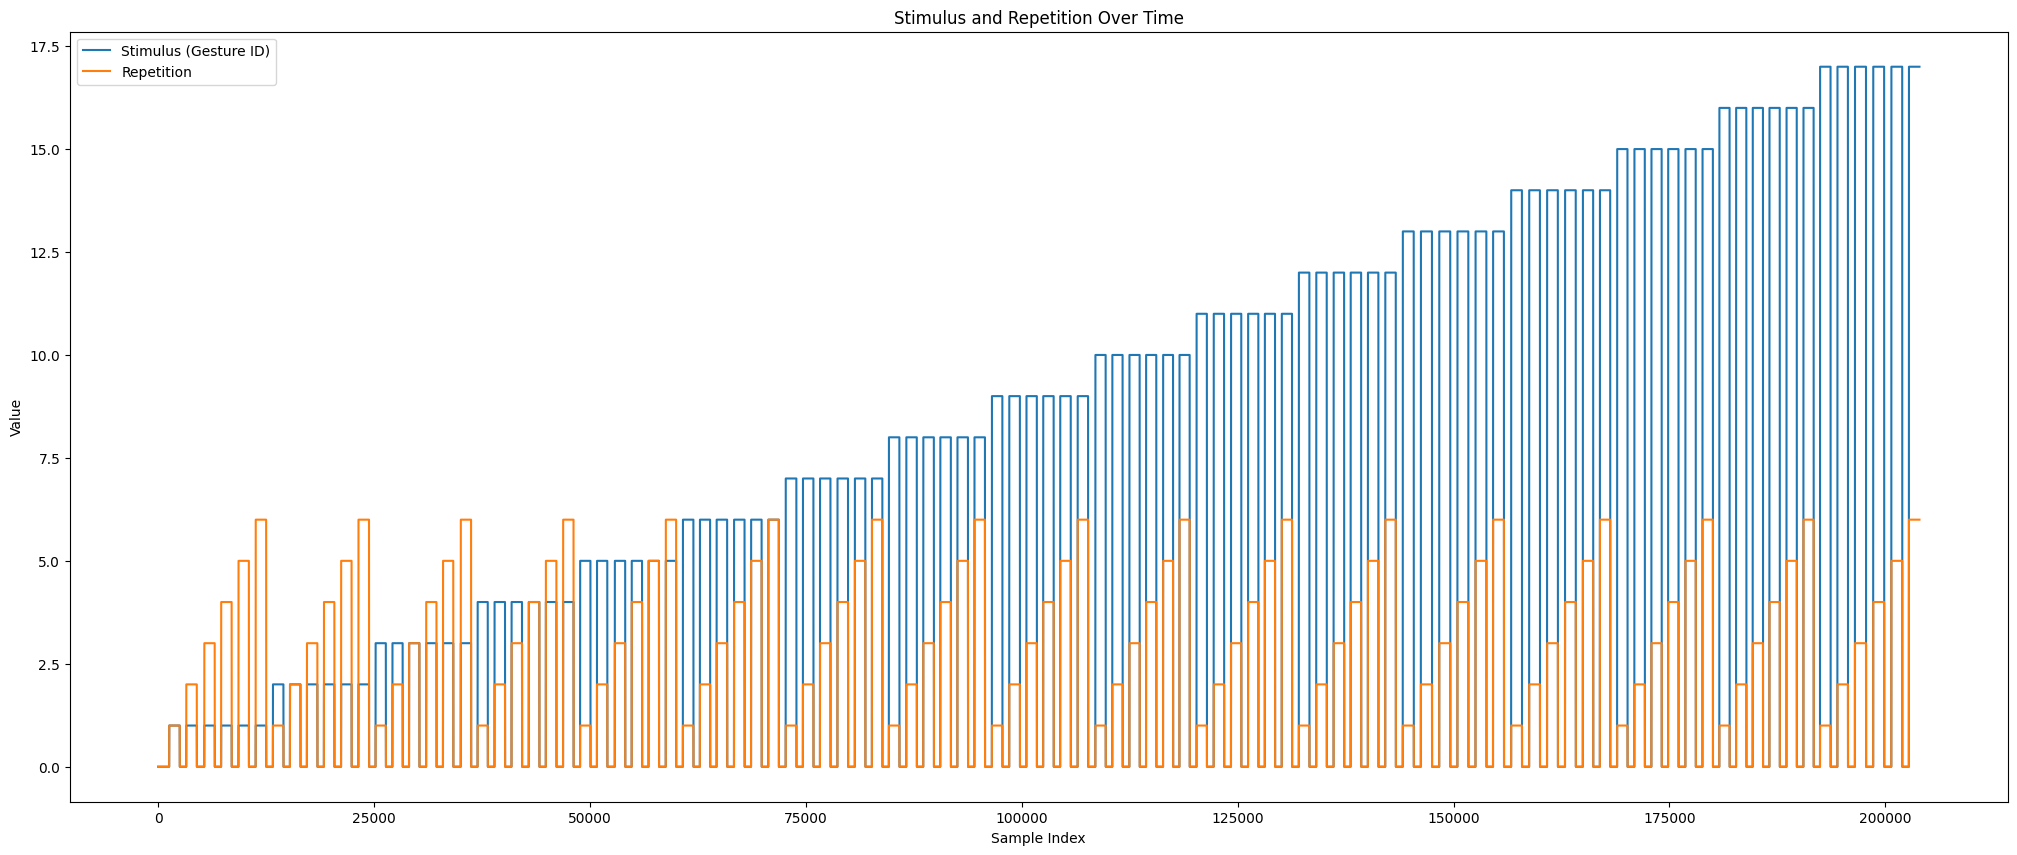

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(25, 10))
plt.plot(stimulus, label='Stimulus (Gesture ID)')
plt.plot(repetition, label='Repetition')
plt.xlabel('Sample Index')
plt.ylabel('Value')
plt.title('Stimulus and Repetition Over Time')
plt.legend()
plt.show()

In [8]:
restimulus = mat['restimulus']
rerepetition = mat['rerepetition']

print(np.unique(restimulus))  # Unique refined gesture labels
print(np.unique(rerepetition))  # Unique refined repetition numbers

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
[0 1 2 3 4 5 6]


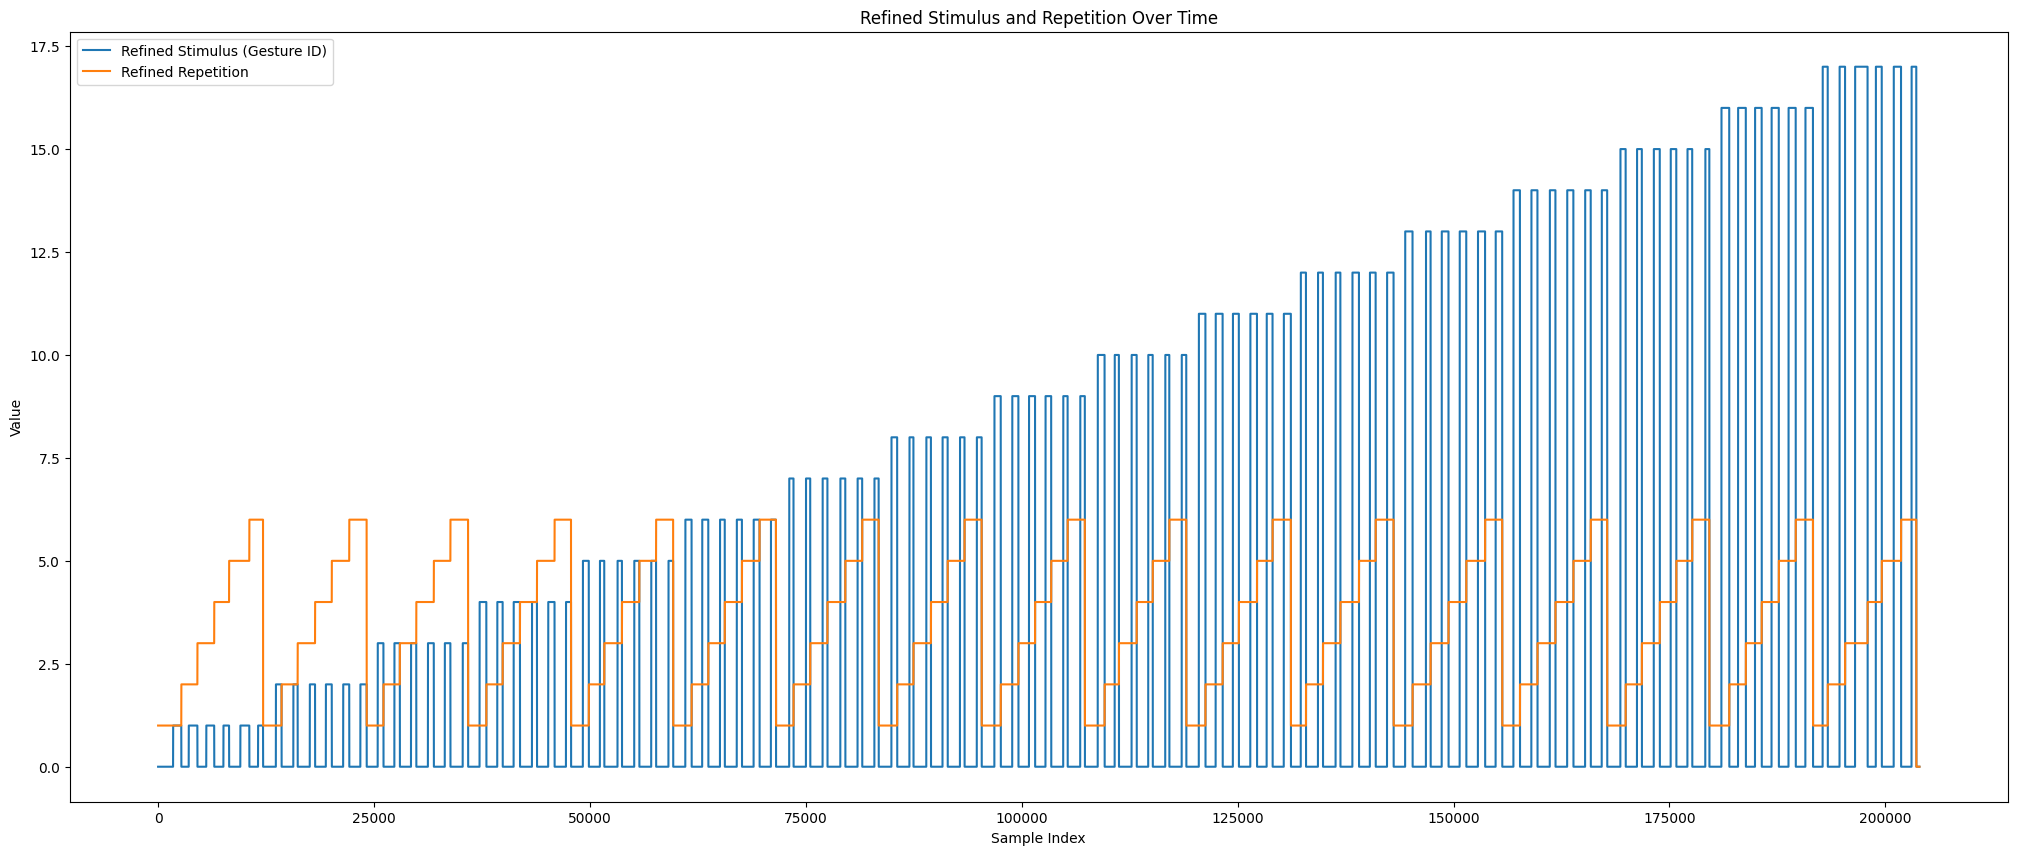

In [9]:
plt.figure(figsize=(25, 10))
plt.plot(restimulus, label='Refined Stimulus (Gesture ID)')
plt.plot(rerepetition, label='Refined Repetition')
plt.xlabel('Sample Index')
plt.ylabel('Value')
plt.title('Refined Stimulus and Repetition Over Time')
plt.legend()
plt.show()

## Check if the masking and segmenting script works with visualisation

In [ ]:
new_run_id = 2
run_key = f"run-{new_run_id:03d}"  # Zero-pad for consistent sorting
print(run_key)

In [ ]:
import h5py
from tqdm import tqdm



def get_global_gesture_id(exercise_id, stimulus_id):
    """NinaPro DB5 has a unique gesture distribution across exercises:
    
    Each exercise has a different set of gestures:

    Exercise 1 (2 in fname, B in docs): 17 gestures (1-17)
    Exercise 2 (3 in fname, C in docs): 23 gestures (18-40)
    Exercise 3 (1 in fname, A in docs): 12 gestures (41-52)
    """

    if stimulus_id == 0: return 0 # Rest is always 0
    
    # Offsets based on the 17, 23, 12 distribution
    if exercise_id == 1:
        return stimulus_id
    elif exercise_id == 2:
        return stimulus_id + 17
    elif exercise_id == 3:
        return stimulus_id + 17 + 23
    return stimulus_id

dataset_dir = "data/ninapro_db5"
output_file = "test.hdf5"

dataset_dir = Path(dataset_dir)
mat_files = sorted(dataset_dir.glob("*.mat"))

with h5py.File(output_file, 'w') as f:
    root = f.create_group("ninapro_db5")
    
    for fpath in tqdm(mat_files, desc="Converting NinaPro DB5"):
        mat = scipy.io.loadmat(str(fpath))
        
        # Extract basic subject info
        # Matlab stores strings/scalars in nested arrays; we flatten them
        subject_id = int(mat['subject'][0][0])
        exercise_id = int(mat['exercise'][0][0])
        fs = int(mat['frequency'][0][0])
        
        subj_key = f"S{subject_id}"
        if subj_key not in root:
            subj_group = root.create_group(subj_key)
            # Static Metadata from the website spec
            subj_group.attrs['age'] = int(mat['age'][0][0])
            subj_group.attrs['gender'] = str(mat['gender'][0])
            subj_group.attrs['weight_kg'] = float(mat['weight'][0][0])
            subj_group.attrs['height_cm'] = float(mat['height'][0][0])
            subj_group.attrs['laterality'] = str(mat['laterality'][0])
            subj_group.attrs['circumference_cm'] = float(mat['circumference'][0][0])
        else:
            subj_group = root[subj_key]

        # Continuous data arrays
        emg = mat['emg'].astype(np.float32)       # (T, 16)
        acc = mat['acc'].astype(np.float32)       # (T, 3) - Note: Only 3 cols for 1st Myo
        glove = mat['glove'].astype(np.float32)   # (T, 22)

        emg /= 128.0  # Normalize Myo EMG to [-1, 1] if raw values are in [-128, 127]
        
        # Use 'restimulus' and 'rerepetition' for refined labels
        stimulus = mat['restimulus'].flatten()
        repetition = mat['rerepetition'].flatten()
        
        # Group by refined trial (rerepetition)
        unique_reps = np.unique(repetition)
        unique_stimuli = np.unique(stimulus)
        print(unique_stimuli)
        i = 0
        
        for rep_idx in unique_reps:
            if rep_idx == 0: continue # Skip rest periods
            
            for stim_idx in unique_stimuli:
                if stim_idx == 0: continue # Skip rest periods
            
                mask = ((repetition == rep_idx) & (stimulus == stim_idx))
                if not np.any(mask):
                    continue
                gesture_ids = np.unique(stimulus[mask])
                print(gesture_ids)
                print(rep_idx)
                print(stim_idx)

                plt.figure(figsize=(25, 10))
                plt.plot(stimulus, label='Refined Stimulus (Gesture ID)')
                plt.plot(repetition, label='Refined Repetition')
                plt.plot(mask.astype(int), label='Current Repetition Mask')  # Highlight current repetition
                plt.xlabel('Sample Index')
                plt.ylabel('Value')
                plt.title('Refined Stimulus and Repetition Over Time')
                plt.legend()
                plt.show()
                i += 1
                if i > 3:
                    break
                continue
                
                # Filter out the '0' label within a repetition mask if it exists
                gesture_ids = gesture_ids[gesture_ids != 0]
                if len(gesture_ids) == 0: continue
                
                gesture_id = int(gesture_ids[0])
                gesture_id = get_global_gesture_id(exercise_id, gesture_id)

                # Create sample group (E=Exercise, R=Repetition, G=Gesture)
                sample_name = f"E{exercise_id}_R{rep_idx}_G{gesture_id}"
                sample_group = subj_group.create_group(sample_name)
                
                # Per-sample Metadata
                sample_group.attrs['gesture_id'] = gesture_id
                sample_group.attrs['repetition_id'] = rep_idx
                
                # 1. EMG (T, 16) 
                # NinaPro EMG is typically recorded in mV or raw units. 
                # Check if you need to scale. If raw Myo, use emg /= 128.0
                sample_group.create_dataset("emg", data=emg[mask], compression="lzf")
                
                # 2. Accel (T, 3)
                sample_group.create_dataset("accel", data=acc[mask], compression="lzf")
                
                # 3. Glove (T, 22) - Kinematic ground truth
                sample_group.create_dataset("glove", data=glove[mask], compression="lzf")
        

In [1]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


In [4]:
import h5py
import numpy as np

with h5py.File("data/ninapro_db5/ninapro_db5.hdf5", 'r') as f:
    root = f["ninapro_db5"]
    run_lengths = []
    for subj_key in root.keys():
        print(f"Subject: {subj_key}")
        subj_group = root[subj_key]
        print(f"  Age: {subj_group.attrs['age']}")
        subj_group = root[subj_key]
        for session_key in subj_group.keys():
            session_group = subj_group[session_key]

            for run_key in session_group.keys():
                run_group = session_group[run_key]

                emg_data = run_group["emg"]
                print(f"  Run: {run_key}, EMG shape: {emg_data.shape}")
                run_lengths.append(emg_data.shape[0])

sample_lengths = np.array(run_lengths)
avg_length = np.mean(sample_lengths)
std = np.std(sample_lengths)
min_length = np.min(sample_lengths)
max_length = np.max(sample_lengths)
print(f"Sample Lengths - Avg: {avg_length:.2f}, Std: {std:.2f}, Min: {min_length}, Max: {max_length}")
print(f"Total Samples: {len(sample_lengths)}")

Subject: sub-1
  Age: 23
  Run: run-001, EMG shape: (928, 16)
  Run: run-002, EMG shape: (652, 16)
  Run: run-003, EMG shape: (873, 16)
  Run: run-004, EMG shape: (978, 16)
  Run: run-005, EMG shape: (951, 16)
  Run: run-006, EMG shape: (963, 16)
  Run: run-007, EMG shape: (710, 16)
  Run: run-008, EMG shape: (630, 16)
  Run: run-009, EMG shape: (647, 16)
  Run: run-010, EMG shape: (688, 16)
  Run: run-011, EMG shape: (659, 16)
  Run: run-012, EMG shape: (631, 16)
  Run: run-013, EMG shape: (725, 16)
  Run: run-014, EMG shape: (653, 16)
  Run: run-015, EMG shape: (770, 16)
  Run: run-016, EMG shape: (733, 16)
  Run: run-017, EMG shape: (742, 16)
  Run: run-018, EMG shape: (766, 16)
  Run: run-019, EMG shape: (708, 16)
  Run: run-020, EMG shape: (752, 16)
  Run: run-021, EMG shape: (772, 16)
  Run: run-022, EMG shape: (780, 16)
  Run: run-023, EMG shape: (758, 16)
  Run: run-024, EMG shape: (827, 16)
  Run: run-025, EMG shape: (604, 16)
  Run: run-026, EMG shape: (765, 16)
  Run: run-02

In [ ]:
import h5py
with h5py.File("data/ninapro_db5/ninapro_db5.hdf5", 'r') as f:
    root = f["ninapro_db5"]
    for subj_key in root.keys():
        print(f"Subject: {subj_key}")
        subj_group = root[subj_key]
        print(subj_group.attrs.keys())  # Print static metadata
        print(subj_group.attrs['age'], subj_group.attrs['gender'], subj_group.attrs['weight_kg'], subj_group.attrs['height_cm'], subj_group.attrs['laterality'], subj_group.attrs['circumference_cm'])
        print(subj_group.keys())  # List all samples for this subject
        for sample_key in subj_group.keys():
            print(f"  Sample: {sample_key}")
            sample_group = subj_group[sample_key]
            print(sample_group.attrs.keys())  # Print per-sample metadata
            emg_data = sample_group["emg"][:]
            accel_data = sample_group["accel"][:]
            glove_data = sample_group["glove"][:]
            print(f"    EMG shape: {emg_data.shape}")
            print(f"    Accel shape: {accel_data.shape}")
            print(f"    Glove shape: {glove_data.shape}")
            

In [ ]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

def analyze_ninapro_hdf5(file_path, root_key="ninapro_db5"):
    data_records = []
    
    with h5py.File(file_path, 'r') as f:
        root = f[root_key]
        subjects = list(root.keys())
        
        for subj in tqdm(subjects, desc="Analyzing subjects"):
            subj_group = root[subj]
            subj_meta = dict(subj_group.attrs)
            
            for trial_name in subj_group.keys():
                # Skip attributes, focus on trial groups
                if not isinstance(subj_group[trial_name], h5py.Group):
                    continue
                    
                trial = subj_group[trial_name]
                trial_meta = dict(trial.attrs)
                
                # Signal metrics
                emg_shape = trial['emg'].shape
                duration_sec = emg_shape[0] / trial_meta.get('sample_rate', 200)
                
                # Combine metadata for flat dataframe
                record = {
                    **subj_meta,
                    **trial_meta,
                    'trial_name': trial_name,
                    'num_samples': emg_shape[0],
                    'duration_sec': duration_sec,
                    'emg_mean': np.mean(trial['emg']),
                    'emg_std': np.std(trial['emg'])
                }
                data_records.append(record)

    df = pd.DataFrame(data_records)
    
    # --- VISUALIZATION ---
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    plt.subplots_adjust(hspace=0.4)

    # 1. Gesture Distribution (Class Balance)
    
    sns.countplot(data=df, x='gesture_id', ax=axes[0,0], palette='viridis')
    axes[0,0].set_title("Sample Count per Gesture ID")
    axes[0,0].set_yscale('log') # Log scale helps see active gestures vs heavy Rest counts
    
    # 2. Trial Durations
    sns.histplot(data=df, x='duration_sec', hue='intra_session_split', multiple="stack", ax=axes[0,1])
    axes[0,1].set_title("Distribution of Trial Durations (Seconds)")

    # 3. Data Leakage Audit (Subject vs Repetition Split)
    
    leak_table = pd.crosstab(df['subject_id'], df['subject_split'])
    sns.heatmap(leak_table, annot=True, cbar=False, ax=axes[1,0], cmap='Blues')
    axes[1,0].set_title("Subject-to-Split Mapping (Zero-Shot Check)")

    # 4. Signal Quality (Mean vs Std per Subject)
    sns.scatterplot(data=df, x='emg_mean', y='emg_std', hue='subject_id', alpha=0.5, ax=axes[1,1])
    axes[1,1].set_title("Signal Energy (Mean vs Std) - Quality Check")
    axes[1,1].get_legend().remove()

    plt.show()

    # --- SUMMARY STATS ---
    print(f"\n{'='*30}\nNINAPRO DB5 AUDIT REPORT\n{'='*30}")
    print(f"Total Subjects: {df['subject_id'].nunique()}")
    print(f"Total Gesture Trials: {len(df)}")
    print(f"Total EMG Hours: {df['duration_sec'].sum() / 3600:.2f}h")
    print(f"\nSplit Distribution (Sessions):")
    print(df['intra_session_split'].value_counts(normalize=True) * 100)
    print(  f"\nSplit Distribution (Subjects):")
    print(df['subject_split'].value_counts(normalize=True) * 100)
    
    return df

# Usage
# df = analyze_ninapro_hdf5("data/ninapro_db5/ninapro_db5.hdf5")

In [ ]:
df = analyze_ninapro_hdf5("data/ninapro_db5/ninapro_db5.hdf5")

In [ ]:
import h5py
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

def analyze_class_length_distribution(hdf5_path, root_key):
    """
    Generic analyzer for the Unified Biosignal HDF5 format.
    Focuses on identifying potential label leakage through signal length distribution.
    
    Args:
        hdf5_path (str): Path to the .hdf5 file.
        root_key (str): The root group name (e.g., 'epn612' or 'ninapro_db5').
    """
    data = []
    
    with h5py.File(hdf5_path, 'r') as f:
        if root_key not in f:
            print(f"Error: Root key '{root_key}' not found in {hdf5_path}")
            return
            
        root = f[root_key]
        
        # Crawl subjects
        for subj_id in tqdm(root.keys(), desc="Extracting trial lengths"):
            subj_group = root[subj_id]
            
            # Crawl sessions/trials
            for sess_id in subj_group.keys():
                if not isinstance(subj_group[sess_id], h5py.Group):
                    continue
                
                sess_group = subj_group[sess_id]
                
                # Ensure emg dataset exists
                if 'emg' not in sess_group:
                    continue
                    
                # Extract metadata
                gesture_id = sess_group.attrs.get('gesture_id', -1)
                sample_rate = sess_group.attrs.get('sample_rate', 200)
                
                # Get length T from shape (T, C)
                length_samples = sess_group['emg'].shape[0]
                duration_sec = length_samples / sample_rate
                
                data.append({
                    'subject_id': subj_id,
                    'gesture_id': gesture_id,
                    'length_samples': length_samples,
                    'duration_sec': duration_sec
                })

    df = pd.DataFrame(data)
    
    if df.empty:
        print("No trials found to analyze.")
        return

    # --- Plotting ---
    plt.figure(figsize=(16, 8))
    
    # Sort by gesture_id for readability
    df = df.sort_values('gesture_id')
    
    # We use a boxenplot or boxplot to show the distribution
    sns.boxplot(data=df, x='gesture_id', y='duration_sec', palette='husl')
    
    # Add a horizontal line for the mean duration to highlight outliers
    plt.axhline(df['duration_sec'].mean(), color='red', linestyle='--', alpha=0.6, label='Global Mean')
    
    plt.title(f"Signal Length Distribution per Class: {root_key.upper()}", fontsize=16)
    plt.xlabel("Gesture ID", fontsize=12)
    plt.ylabel("Duration (seconds)", fontsize=12)
    plt.legend()
    plt.grid(axis='y', linestyle=':', alpha=0.7)
    
    # If there are many classes (e.g., EPN612), thin out the x-labels
    if df['gesture_id'].nunique() > 20:
        plt.xticks(rotation=90, fontsize=8)
    
    plt.tight_layout()
    plt.show()

    # --- Statistical Leakage Check ---
    # Calculate variance of lengths per class
    stats = df.groupby('gesture_id')['duration_sec'].agg(['mean', 'std', 'count'])
    print("\n--- Length Statistics per Class ---")
    print(stats.head(10)) # Print first 10 for brevity
    
    # Check if any class is perfectly predictable by length (std == 0)
    leakage_candidates = stats[stats['std'] < 0.001]
    if not leakage_candidates.empty:
        print("\n⚠️ WARNING: Potential Label Leakage Detected!")
        print("The following classes have zero or near-zero variation in length.")
        print("A model could simply learn the sequence length to identify these classes:")
        print(leakage_candidates.index.tolist())
    else:
        print("\n✅ Clean: No classes have a unique, fixed length signature.")

In [ ]:
analyze_class_length_distribution("data/ninapro_db5/ninapro_db5.hdf5", root_key="ninapro_db5")

In [ ]:
%cd ..

In [ ]:
import h5py
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm

def extract_dataset_metadata(hdf5_path, root_key):
    """
    Crawls a unified biosignal HDF5 file and flattens metadata into a DataFrame.
    """
    records = []
    with h5py.File(hdf5_path, 'r') as f:
        if root_key not in f:
            raise KeyError(f"Root key '{root_key}' not found in {hdf5_path}")
        
        root = f[root_key]
        for subj_id in tqdm(root.keys(), desc=f"Scanning {root_key}"):
            subj_group = root[subj_id]
            subj_meta = dict(subj_group.attrs)
            
            for sess_id in subj_group.keys():
                if not isinstance(subj_group[sess_id], h5py.Group):
                    continue
                
                sess_group = subj_group[sess_id]
                sess_meta = dict(sess_group.attrs)

                for run_key in sess_group.keys():
                    if not isinstance(sess_group[run_key], h5py.Group):
                        continue
                    
                    run_group = sess_group[run_key]
                    run_meta = dict(run_group.attrs)
                
                    # Signal metrics
                    emg_data = run_group['emg']
                    t, c = emg_data.shape
                    fs = run_group['emg'].attrs['sample_rate']
                    # fs = sess_meta.get('sample_rate', 200)
                    
                    # Combine metadata
                    record = {
                        **subj_meta,
                        **sess_meta,
                        **run_meta,
                        'subj_key': subj_id,
                        'sess_key': sess_id,
                        'run_key': run_key,
                        'num_samples': t,
                        'num_channels': c,
                        'duration_sec': t / fs,
                        'emg_mean': np.mean(emg_data),
                        'emg_std': np.std(emg_data)
                    }
                    records.append(record)
                
    df = pd.DataFrame(records)
    # Ensure participant_id is a sortable type (int if possible, else string)
    # Ensure participant_num is a sortable type (int if possible)
    # Participarn ID is often a string like "subject_01", so we can extract the numeric part for sorting
    try:
        regex = re.compile(r'\d+')
        df['participant_number'] = df['participant_id'].apply(lambda x: int(regex.search(str(x)).group()) if regex.search(str(x)) else x)
        df.sort_values('participant_number', inplace=True)
    except:
        pass
        
    return df

In [16]:
df = extract_dataset_metadata("data/ninapro_db5/ninapro_db5.hdf5", root_key="ninapro_db5")

Scanning ninapro_db5: 100%|██████████| 10/10 [00:01<00:00,  6.87it/s]


In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

class BiosignalAuditor:
    def __init__(self, df, dataset_name="Dataset"):
        self.df = df
        self.name = dataset_name.upper()
        # Filter out unlabelled for core distribution plots
        self.df_clean = df[df['gesture_id'] != -1].copy()
        
        plt.style.use('seaborn-v0_8-muted')
        sns.set_context("talk")

    def run_full_audit(self):
        """Executes all visualization and statistical checks."""
        self.plot_overview()
        self.plot_length_leakage_check()
        self.print_summary()

    def plot_overview(self):
        fig, axes = plt.subplots(5, 2, figsize=(40, 50))
        plt.subplots_adjust(hspace=0.4)
            
        # 1. Class Distribution (Gesture ID)
        # This checks for "Label Imbalance"
        sns.countplot(data=self.df, x='gesture_id', hue='intra_session_split', ax=axes[0,0])
        axes[0,0].set_title("Gesture Class Distribution (Intra-Session Split)")
        axes[0,0].tick_params(axis='x', rotation=45)


        sns.countplot(data=self.df, x='gesture_id', hue='inter_subject_split', ax=axes[0,1])
        axes[0,1].set_title("Gesture Class Distribution (Inter-Subject Split)")
        axes[0,1].tick_params(axis='x', rotation=45)


        # 2. Duration Distribution
        sns.histplot(data=self.df_clean, x='duration_sec', hue='intra_session_split', multiple="stack", ax=axes[1,0])
        axes[1,0].set_title("Distribution of Trial Durations - Intra-session split (Seconds)")

        sns.histplot(data=self.df_clean, x='duration_sec', hue='inter_subject_split', multiple="stack", ax=axes[1,1])
        axes[1,1].set_title("Distribution of Trial Durations - Inter-subject split (Seconds)")

        # 3. Leakage Heatmap (Subject-to-Split Mapping)
        leak_table = pd.crosstab(self.df['participant_id'], self.df['intra_session_split'])
        sns.heatmap(leak_table, annot=True, cbar=False, cmap='Blues', ax=axes[2,0])
        axes[2,0].set_title("Session Leakage Check")

        leak_table = pd.crosstab(self.df['participant_id'], self.df['inter_subject_split'])
        sns.heatmap(leak_table, annot=True, cbar=False, cmap='Blues', ax=axes[2,1])
        axes[2,1].set_title("Subject Leakage Check")


        # 4. 


        # 5. Signal Quality (Mean vs Std per Subject)
        sns.scatterplot(data=self.df_clean, x='emg_mean', y='emg_std', hue='participant_id', alpha=0.5, ax=axes[3,1])
        axes[3,1].set_title("Signal Energy (Mean vs Std) - Quality Check")
        axes[3,1].get_legend().remove()


        # 6. Sex Distribution pie chart
        axes[4,0].pie(self.df_clean['sex'].value_counts(), labels=self.df_clean['sex'].unique(), autopct='%1.1f%%', colors=sns.color_palette('Set2')) 
        axes[4,0].set_title("Gender Distribution")

        # 7. Handedness Distribution
        axes[4,1].pie(self.df_clean['handedness'].value_counts(), labels=self.df_clean['handedness'].unique(), autopct='%1.1f%%', colors=sns.color_palette('Set2'))
        axes[4,1].set_title("Handedness Distribution")


        plt.show()

    def plot_length_leakage_check(self):
        """Checks if gesture ID is perfectly predictable by signal duration."""
        plt.figure(figsize=(16, 6))
        sns.boxplot(data=self.df_clean.sort_values('gesture_id'), x='gesture_id', y='duration_sec', palette='husl')
        plt.axhline(self.df_clean['duration_sec'].mean(), color='red', linestyle='--', alpha=0.6, label='Global Mean')
        plt.title(f"{self.name}: Signal Length Leakage Audit")
        plt.xticks(rotation=90 if self.df_clean['gesture_id'].nunique() > 10 else 0)
        plt.legend()
        plt.show()

    def print_summary(self):
        print(f"\n{'='*40}\n{self.name} AUDIT REPORT\n{'='*40}")
        print(f"Total Subjects: {self.df['participant_id'].nunique()}")
        print(f"Total Trials:   {len(self.df)}")
        print(f"Total EMG Time: {self.df['duration_sec'].sum() / 3600:.2f} hours")
        
        for col in ['intra_session_split', 'intra_session_split', 'subject_split', 'inter_subject_split']:
            if col in self.df.columns:
                print(f"\nSplit Distribution ({col}):")
                print(self.df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

        # Check for Inter-Subject Leakage
        subj_split_col = next((c for c in ['subject_split', 'inter_subject_split'] if c in self.df.columns), None)
        if subj_split_col:
            leak_check = self.df.groupby('participant_id')[subj_split_col].nunique()
            leaked = leak_check[leak_check > 1].index.tolist()
            if leaked:
                print(f"\n⚠️ WARNING: {len(leaked)} subjects found in multiple splits: {leaked[:5]}...")
            else:
                print("\n✅ Clean: No subject leakage detected across splits.")

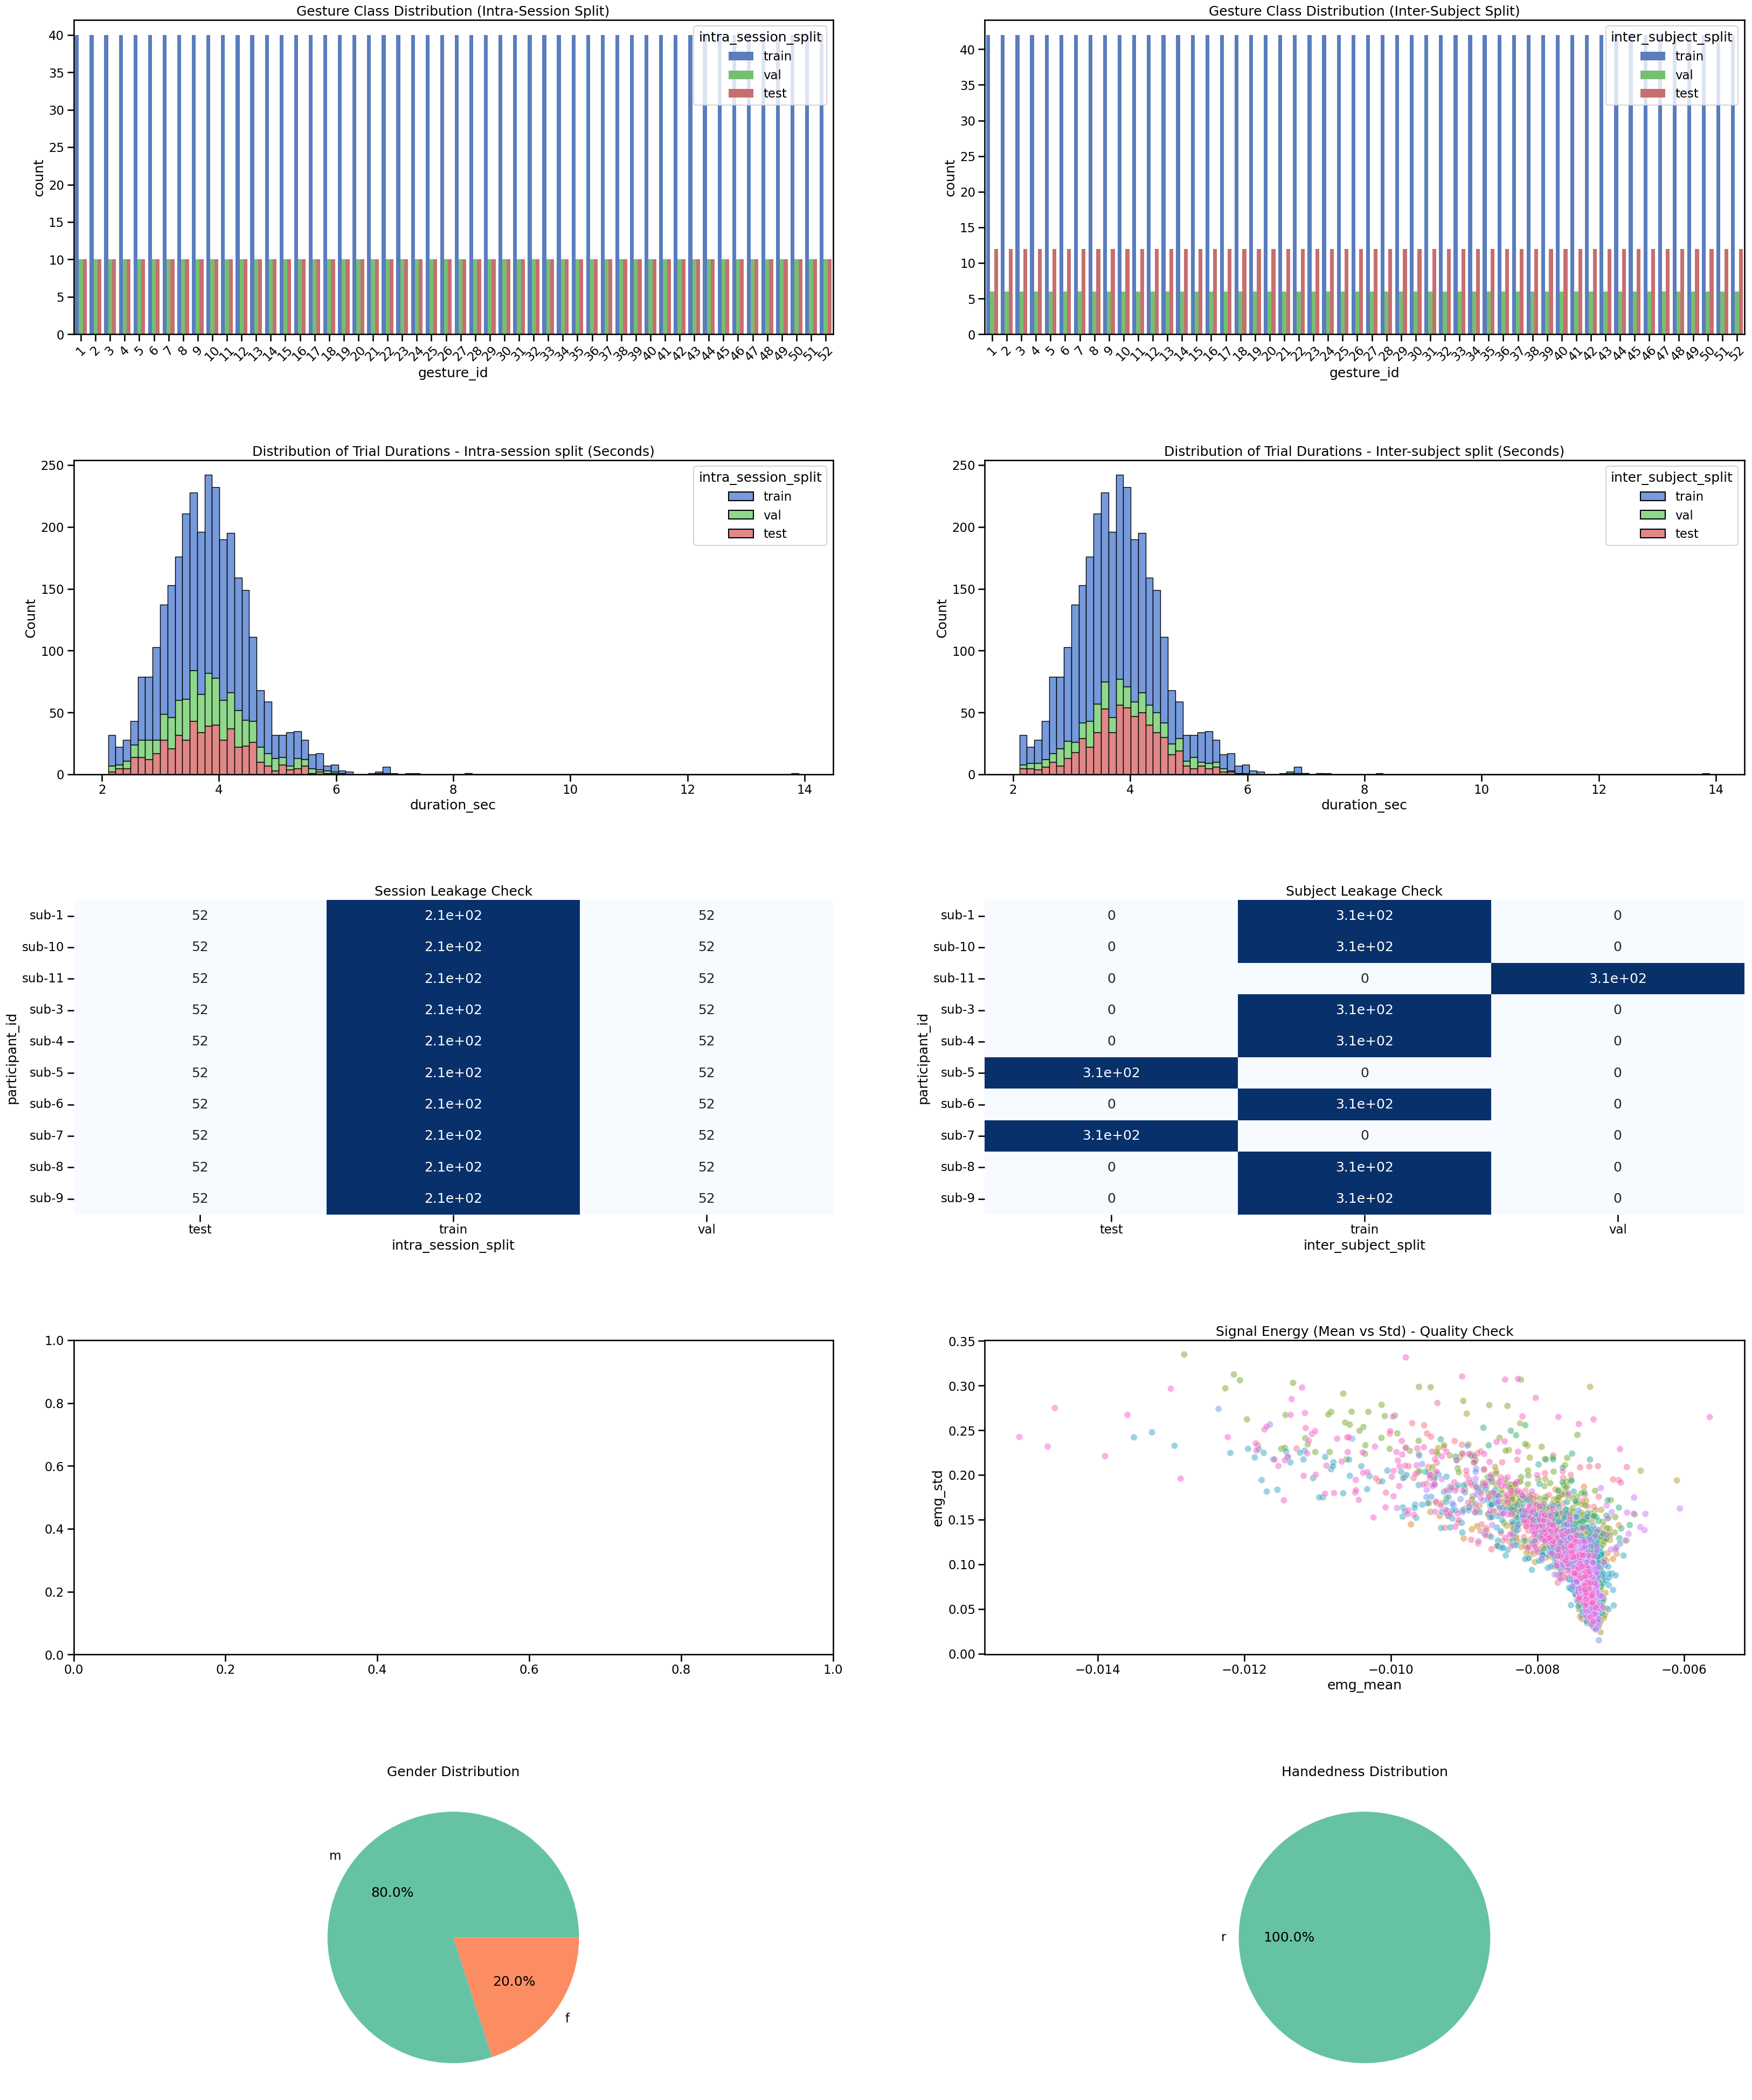

/tmp/ipykernel_2790226/1090188438.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=self.df_clean.sort_values('gesture_id'), x='gesture_id', y='duration_sec', palette='husl')


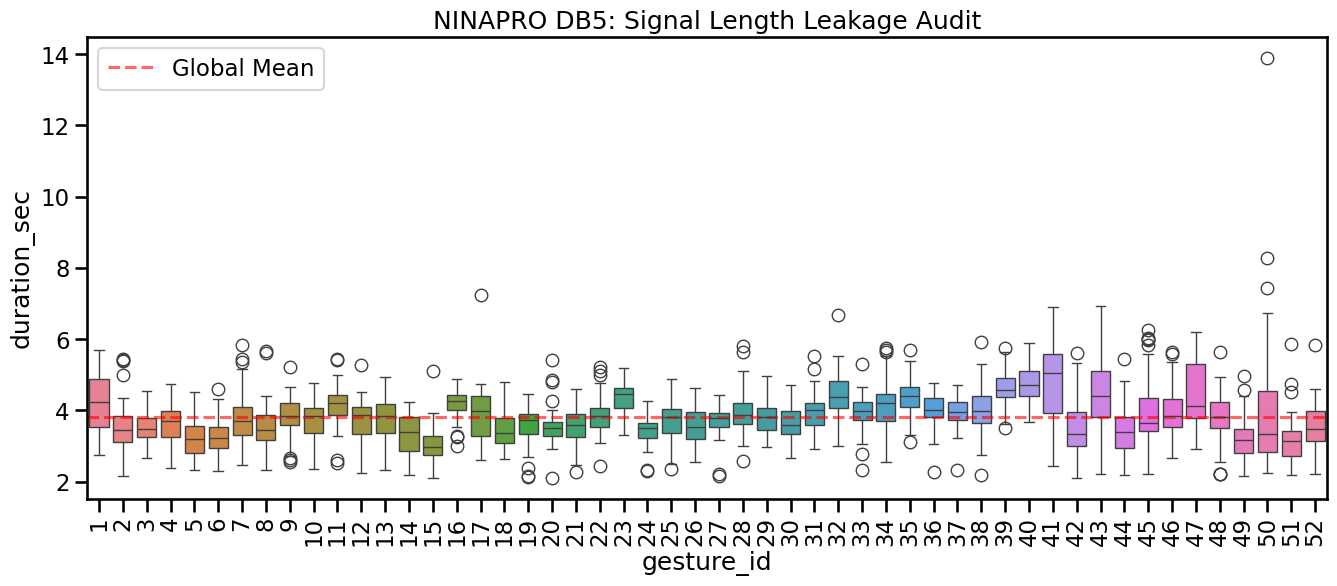


NINAPRO DB5 AUDIT REPORT
Total Subjects: 10
Total Trials:   3120
Total EMG Time: 3.31 hours

Split Distribution (intra_session_split):
intra_session_split
train    66.67%
val      16.67%
test     16.67%
Name: proportion, dtype: object

Split Distribution (intra_session_split):
intra_session_split
train    66.67%
val      16.67%
test     16.67%
Name: proportion, dtype: object

Split Distribution (inter_subject_split):
inter_subject_split
train    70.0%
test     20.0%
val      10.0%
Name: proportion, dtype: object

✅ Clean: No subject leakage detected across splits.


In [36]:
auditor = BiosignalAuditor(df, "NinaPro DB5")
auditor.run_full_audit()

In [43]:
def plot_global_amplitude_histogram(hdf5_path, root_key, n_runs_to_sample=50):
    """
    Plots a histogram of all raw EMG datapoints across a subset of runs.
    This reveals the statistical distribution (PDF) of the signal.
    """
    all_values = []
    
    with h5py.File(hdf5_path, 'r') as f:
        for subj_id in f[root_key].keys():
            subj_group = f[root_key][subj_id]
            for sess_id in subj_group.keys():
                sess_group = subj_group[sess_id]
                for run_key in sess_group.keys():
                    run_group = sess_group[run_key]
                    emg_data = run_group['emg'][:]
                    all_values.extend(emg_data.flatten())
    
    all_values = np.array(all_values)

    plt.figure(figsize=(12, 6))
    
    # Using a log scale for the Y-axis is often better for EMG 
    # because the 'Rest' zeros dominate the count.
    sns.histplot(all_values, bins=100, kde=True, color='teal')
    
    plt.yscale('log') 
    plt.title(f"{root_key}: Global Amplitude Distribution (All Datapoints)")
    plt.xlabel("Amplitude (Normalized units)")
    plt.ylabel("Frequency (Log Scale)")
    plt.grid(True, which="both", ls="-", alpha=0.2)
    
    # Add vertical lines for standard deviations
    std = np.std(all_values)
    plt.axvline(std, color='orange', linestyle='--', label=f'1 Std ({std:.2f})')
    plt.axvline(-std, color='orange', linestyle='--')
    plt.legend()
    
    plt.show()

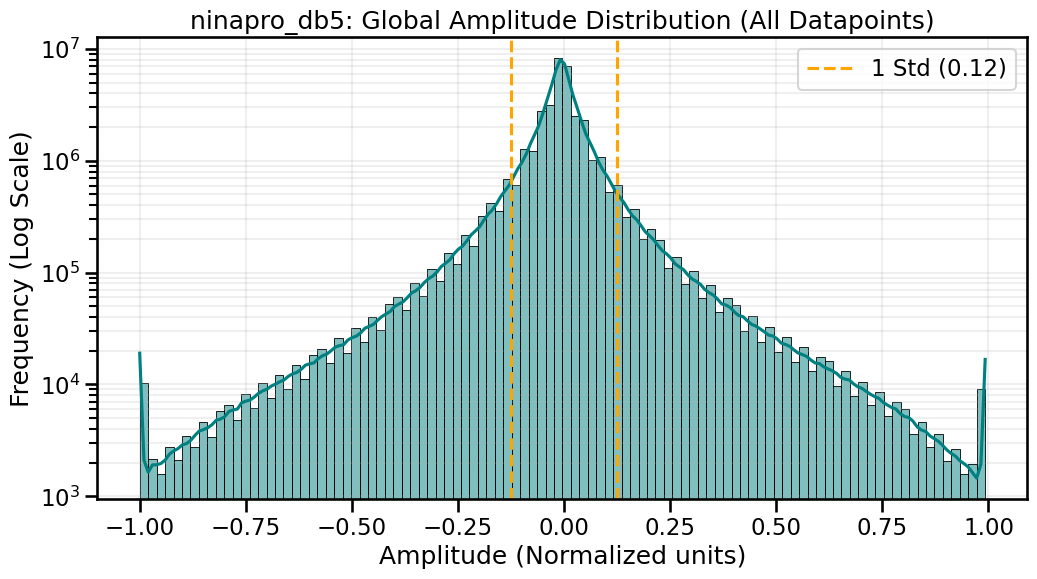

In [44]:
plot_global_amplitude_histogram("data/ninapro_db5/ninapro_db5.hdf5", "ninapro_db5", n_runs_to_sample=50)